<a href="https://colab.research.google.com/github/gaurav8798/CropCareAi/blob/main/Crop_Care_Ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Install & Import Dependencies
First, we'll configure our Python environment by installing the necessary deep learning libraries (**TensorFlow Datasets**) and the user interface library (**Gradio**).

In [ ]:
%pip -q install tensorflow-datasets gradio importlib-resources

import os
import json
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
import gradio as gr

import importlib
importlib.invalidate_caches()

print('TensorFlow Version:', tf.__version__)

TensorFlow Version: 2.21.0


### Step 2: Configure & Load Dataset
We define standard configurations (like Image Size and Batch Size) and load the PlantVillage dataset splits directly using TensorFlow Datasets.

In [ ]:
# Configuration parameters
IMG_SIZE = 160
BATCH_SIZE = 32

# Load PlantVillage train, validation, and test splits
print("Loading dataset...")
(train_raw, val_raw, test_raw), info = tfds.load(
    'plant_village',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    as_supervised=True,
    with_info=True
)

# Extract names of all classes
all_classes = info.features['label'].names
# Select only the Tomato-related classes
tomato_classes = [name for name in all_classes if name.lower().startswith('tomato')]
print("Detected Tomato Classes:\n", tomato_classes)

# Map original dataset indices to sequential indices (0 to 9)
tomato_ids = [info.features['label'].str2int(name) for name in tomato_classes]
label_mapping = {original_id: idx for idx, original_id in enumerate(tomato_ids)}

# Helper function to preprocess images and filter tomato classes
def preprocess(image, label):
    # Resize and normalize image
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    # Map label to our new simplified tomato label
    # Using a simple python dictionary mapping wrapped in tf.numpy_function
    def map_label(lbl):
        return np.int32(label_mapping.get(int(lbl), -1))

    mapped_lbl = tf.numpy_function(map_label, [label], tf.int32)
    return image, mapped_lbl

# Filter out non-tomato leaves
def is_tomato(image, label):
    return label >= 0

# Build clean pipelines
def build_pipeline(dataset, shuffle=False):
    dataset = dataset.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.filter(is_tomato)
    if shuffle:
        dataset = dataset.shuffle(1000)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = build_pipeline(train_raw, shuffle=True)
val_ds = build_pipeline(val_raw)
test_ds = build_pipeline(test_raw)

print("Dataset pipelines are ready!")

Loading dataset...
Detected Tomato Classes:
 ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_mosaic_virus', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Dataset pipelines are ready!


### Step 2.5: Exploratory Data Analysis (EDA)
Before feeding our data directly to a model, let's explore our dataset's balance by plotting class distributions and visualizing a few sample images.

Calculating class distribution...


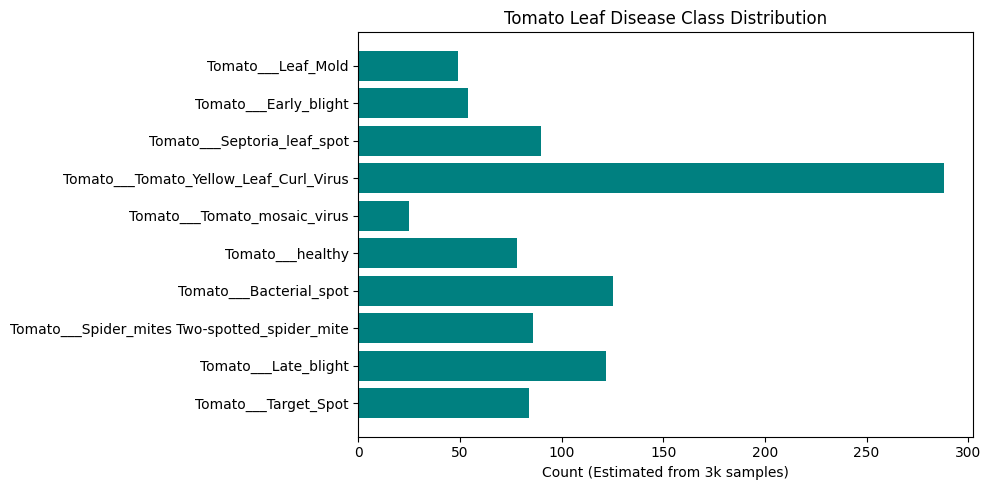

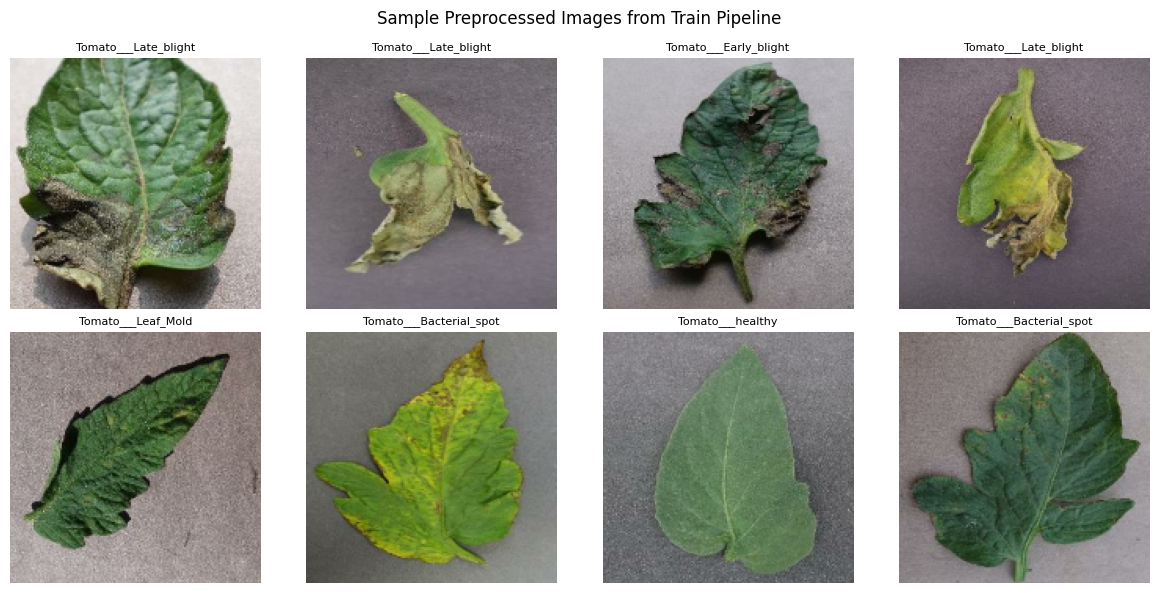

In [ ]:
import matplotlib.pyplot as plt
import collections

# 1. Analyze and visualize class distributions
print("Calculating class distribution...")
label_counts = collections.defaultdict(int)

# Safely iterate through some of the raw training dataset to count labels
for _, label in train_raw.take(3000):
    lbl_idx = label_mapping.get(int(label), -1)
    if lbl_idx >= 0:
        label_counts[tomato_classes[lbl_idx]] += 1

# Plot distribution
plt.figure(figsize=(10, 5))
plt.barh(list(label_counts.keys()), list(label_counts.values()), color='teal')
plt.xlabel("Count (Estimated from 3k samples)")
plt.title("Tomato Leaf Disease Class Distribution")
plt.tight_layout()
plt.show()

# 2. Visualize sample preprocessed images from the dataset pipeline
plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        # Re-scale back to [0, 255] for plotting
        img_to_show = images[i].numpy().astype("uint8")
        plt.imshow(img_to_show)
        plt.title(tomato_classes[labels[i].numpy()], fontsize=8)
        plt.axis("off")
plt.suptitle("Sample Preprocessed Images from Train Pipeline")
plt.tight_layout()
plt.show()

### Step 3: Build & Train the Neural Network
We load MobileNetV2 with pre-trained ImageNet weights, freeze its base layers to preserve existing features, attach a classification head, and train it directly on our tomato dataset.

In [ ]:
# 1. Redefine pipeline helper functions to explicitly set shapes (preventing the "unknown rank" error)
def preprocess_fixed(image, label):
    # Resize and normalize image
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Use tf.numpy_function to map label
    def map_label(lbl):
        return np.int32(label_mapping.get(int(lbl), -1))

    mapped_lbl = tf.numpy_function(map_label, [label], tf.int32)

    # EXPLICITLY SET TENSOR SHAPES (This fixes the ValueError: unknown rank!)
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    mapped_lbl.set_shape(())
    return image, mapped_lbl

def is_tomato(image, label):
    return label >= 0

def build_pipeline_fixed(dataset, shuffle=False):
    dataset = dataset.map(preprocess_fixed, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.filter(is_tomato)
    if shuffle:
        dataset = dataset.shuffle(1000)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Re-apply fixed pipeline to train, validation, and test datasets
train_ds = build_pipeline_fixed(train_raw, shuffle=True)
val_ds = build_pipeline_fixed(val_raw)
test_ds = build_pipeline_fixed(test_raw)

# 2. Build and compile MobileNetV2
base_model = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze pre-trained weights

model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Rescaling(1./127.5, offset=-1), # Normalize pixels to range [-1, 1]
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(tomato_classes), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train for 5 simple epochs
print("Starting training with fixed shapes...")
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Starting training with fixed shapes...
Epoch 1/5
    455/Unknown 359s 768ms/step - accuracy: 0.6580 - loss: 1.0532

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


455/455 ━━━━━━━━━━━━━━━━━━━━ 402s 863ms/step - accuracy: 0.7793 - loss: 0.6747 - val_accuracy: 0.8861 - val_loss: 0.3628
Epoch 2/5
455/455 ━━━━━━━━━━━━━━━━━━━━ 445s 869ms/step - accuracy: 0.8960 - loss: 0.3221 - val_accuracy: 0.9119 - val_loss: 0.2824
Epoch 3/5
455/455 ━━━━━━━━━━━━━━━━━━━━ 376s 820ms/step - accuracy: 0.9118 - loss: 0.2647 - val_accuracy: 0.9209 - val_loss: 0.2492
Epoch 4/5
455/455 ━━━━━━━━━━━━━━━━━━━━ 383s 835ms/step - accuracy: 0.9230 - loss: 0.2322 - val_accuracy: 0.9232 - val_loss: 0.2277
Epoch 5/5
455/455 ━━━━━━━━━━━━━━━━━━━━ 455s 861ms/step - accuracy: 0.9307 - loss: 0.2104 - val_accuracy: 0.9310 - val_loss: 0.2280


### Step 4: Evaluate & Launch Web App
We test our model and immediately deploy an interactive interface where you can drag and drop any tomato leaf image to see live predictions.

In [ ]:
# Evaluate accuracy on test dataset
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nTest accuracy: {test_acc * 100:.2f}%")

# Define Gradio prediction function
def classify_leaf(image):
    if image is None:
        return "Please upload an image."
    # Preprocess image
    img = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    img = tf.expand_dims(img, axis=0) # Add batch dimension

    # Predict probabilities
    predictions = model.predict(img)[0]

    # Return class name mapped to confidence score
    return {tomato_classes[i]: float(predictions[i]) for i in range(len(tomato_classes))}

# Launch Gradio interface
demo = gr.Interface(
    fn=classify_leaf,
    inputs=gr.Image(label="Upload Tomato Leaf Image"),
    outputs=gr.Label(num_top_classes=3, label="Predictions"),
    title="CropCare AI - Beginner Friendly Demo",
    description="Upload any tomato leaf image to diagnose health issues using our simplified MobileNetV2 model!"
)

demo.launch(share=True)

58/58 ━━━━━━━━━━━━━━━━━━━━ 44s 743ms/step - accuracy: 0.9275 - loss: 0.2146

Test accuracy: 92.75%


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://924e08d792cbe73c2a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
*Developed with ❤️ for CropCare AI beginners.*